# Лабораторная 2 NumPy и анализ заказов в Pandas

**Иноземцев Сергей Викторович · ЕТ-216**


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
DATA = Path('lab2') if Path('lab2').is_dir() else Path('.')

def show(name=None):
    """Показать график в ноутбуке без создания внешних файлов."""
    plt.tight_layout()
    plt.show()
    plt.close('all')


## A NumPy и статистические выводы

### 1.1 Свойства массивов
Создать массивы заказов; вывести shape, ndim, size и проверить согласованность наблюдений.

In [2]:
delivery_time = np.array([35, 42, 28, 51, 39, 63, 31, 45])
order_price = np.array([1200, 3500, 800, 4200, 1900, 5600, 1500, 2800])
items_count = np.array([2, 5, 1, 7, 3, 8, 2, 4])
display(pd.DataFrame({'shape': [delivery_time.shape, order_price.shape, items_count.shape], 'ndim': [delivery_time.ndim, order_price.ndim, items_count.ndim], 'size': [delivery_time.size, order_price.size, items_count.size]}, index=['time', 'price', 'items']))
assert delivery_time.size == order_price.size == items_count.size

,shape,ndim,size
time,"(8,)",1,8
price,"(8,)",1,8
items,"(8,)",1,8


size=8 означает восемь измерений, то есть восемь заказов в каждом одномерном массиве. Один индекс должен описывать один заказ, иначе признаки будут ошибочно сопоставлены. При длинах 8 и 7 поэлементные операции дадут ошибку broadcasting; усечение до семи скроет потерянную запись и исказит анализ.

### 1.2 Матрица и индексация

In [3]:
orders = np.column_stack((delivery_time, order_price, items_count))
print('shape:', orders.shape, 'size:', orders.size)
print('Первый заказ:', orders[0])
print('Время:', orders[:, 0])
print('Стоимость:', orders[:, 1])
print('Товаров в шестом:', orders[5, 2])
print('С третьего заказа:\n', orders[2:])
print('Первые пять, два признака:\n', orders[:5, :2])

shape: (8, 3) size: 24
Первый заказ: [  35 1200    2]
Время: [35 42 28 51 39 63 31 45]
Стоимость: [1200 3500  800 4200 1900 5600 1500 2800]
Товаров в шестом: 8
С третьего заказа:
 [[  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
Первые пять, два признака:
 [[  35 1200]
 [  42 3500]
 [  28  800]
 [  51 4200]
 [  39 1900]]


shape=(8,3) — восемь заказов с тремя признаками. size=24 — число отдельных значений во всей матрице.

### 1.3 Представление и копия

In [4]:
delivery = orders[:, 0]
delivery[0] = 1000
print('После изменения view:\n', orders)
assert orders[0, 0] == 1000
orders[0, 0] = 35
delivery_copy = orders[:, 0].copy()
delivery_copy[0] = 1000
print('После изменения copy:\n', orders)
assert orders[0, 0] == 35
print('Общая память view:', np.shares_memory(orders, delivery), '; copy:', np.shares_memory(orders, delivery_copy))

После изменения view:
 [[1000 1200    2]
 [  42 3500    5]
 [  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
После изменения copy:
 [[  35 1200    2]
 [  42 3500    5]
 [  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
Общая память view: True ; copy: False


Срез view использует память исходной матрицы. copy создаёт независимые данные. Например, замена выбросов в view при предварительной обработке незаметно изменит исходную таблицу и сделает сравнение «до и после» неверным.

### 1.4 и 1.5 Булевы маски

In [5]:
problem = delivery_time > 45
large = (order_price > 3000) & (items_count > 4)
print('Маска:', problem, '; проблемные:', delivery_time[problem])
print('Число:', problem.sum(), '; среднее:', delivery_time[problem].mean())
print('Крупные: цены', order_price[large], '; время', delivery_time[large], '; среднее', delivery_time[large].mean())
print('>45:', problem.sum(), '; >=45:', (delivery_time >= 45).sum())

Маска: [False False False  True False  True False False] ; проблемные: [51 63]
Число: 2 ; среднее: 57.0
Крупные: цены [3500 4200 5600] ; время [42 51 63] ; среднее 52.0
>45: 2 ; >=45: 3


Строгое условие исключает заказ с временем ровно 45 минут: при ≥45 проблемных заказов уже три вместо двух. Комбинация признаков выделяет сегмент крупных многопозиционных заказов: в среднем магазин может укладываться в норматив, а именно этот сегмент — задерживаться.

### 2.1 Влияние выброса

In [6]:
x = np.array([8, 9, 10, 11, 12])
bad = np.append(x, 1000)
display(pd.DataFrame({'среднее': [x.mean(), bad.mean()], 'медиана': [np.median(x), np.median(bad)]}, index=['до', 'после']))

,среднее,медиана
до,10.0,10.0
после,175.0,10.5


Среднее выросло с 10 до 175, медиана — с 10 до 10,5. Среднее учитывает величину каждого наблюдения, медиана зависит от центральных порядковых позиций. Для типичного времени при редких экстремумах устойчивее медиана; для планирования общих затрат времени полезно среднее, поскольку оно учитывает и дорогие редкие случаи.

### 2.2 Процентили и SLA

In [7]:
np.random.seed(42)
sim = np.random.normal(30, 5, 1000)
q = np.quantile(sim, [0.5, 0.9, 0.95, 0.99])
print('Среднее, std(ddof=0), медиана:', sim.mean(), sim.std(), np.median(sim))
display(pd.Series(q, index=['p50', 'p90', 'p95', 'p99']))
print('Доля <=40:', np.mean(sim <= 40), 'SLA выполнен:', q[1] <= 40)

Среднее, std(ddof=0), медиана: 30.096660279111628 4.893631038736771 30.12650306117444


p50    30.126503
p90    36.528226
p95    38.384863
p99    41.579848
dtype: float64

Доля <=40: 0.976 SLA выполнен: True


SLA на смоделированных данных выполнен: p90=36.53 <40 минут. p90 и p95 ограничивают соответственно 90% и 95% доставок; p95=38.38 и p99=41.58 показывают более медленный хвост. Параметры выборки близки к 30 и 5, но не совпадают точно из-за случайной вариации. Ориентация на p95 потребует контролировать ещё 5% наиболее медленных доставок. Симуляция не доказывает соблюдение SLA реальным магазином.

### 2.3 Предсказуемость служб

In [8]:
A = np.array([28, 29, 30, 31, 32])
B = np.array([15, 20, 30, 40, 45])
display(pd.DataFrame({'mean': [A.mean(), B.mean()], 'median': [np.median(A), np.median(B)], 'std_ddof0': [A.std(), B.std()], 'p90': [np.quantile(A, 0.9), np.quantile(B, 0.9)]}, index=['A', 'B']))

,mean,median,std_ddof0,p90
A,30.0,30.0,1.414214,31.6
B,30.0,30.0,11.401754,43.0


У обеих служб среднее и медиана 30 минут, но A предсказуемее: меньше стандартное отклонение и p90. Для дорогой электроники при прочих равных выбрана A; дополнительно нужны данные о повреждениях, цене и надёжности, которых в примере нет.

### 2.4 и 2.5 Корреляция и скрытые факторы

Pearson r: 0.9343293664033213


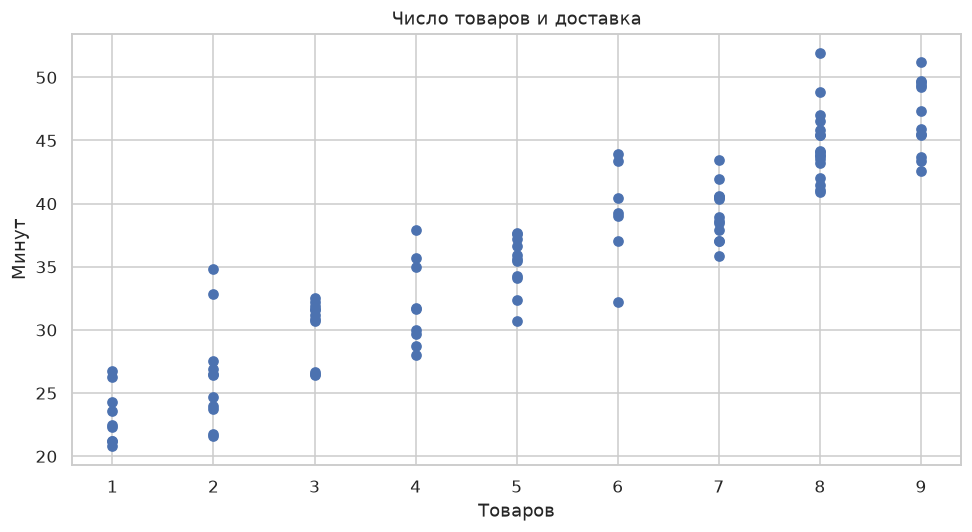

In [9]:
np.random.seed(42)
items = np.random.randint(1, 10, 100)
correlated = 20 + 3 * items + np.random.normal(0, 3, 100)
r = np.corrcoef(items, correlated)[0, 1]
print('Pearson r:', r)
plt.scatter(items, correlated)
plt.xlabel('Товаров')
plt.ylabel('Минут')
plt.title('Число товаров и доставка')
show('correlation')

Связь сильная положительная: больше позиций может требовать больше времени на сборку. Из корреляции наблюдаемых данных причинность не следует: возможны смешивающие факторы, например размер склада или сложность заказа. В примере с мороженым общий фактор — жара/лето: растут покупки и число купающихся. Другой пример: рекламные расходы и выручка одновременно растут перед праздниками; сезонность мешает приписать весь прирост рекламе.

### 3.1 Bootstrap среднего

Среднее: 32.5 ; центральный 95% bootstrap ДИ: [29.16666667 37.66666667]


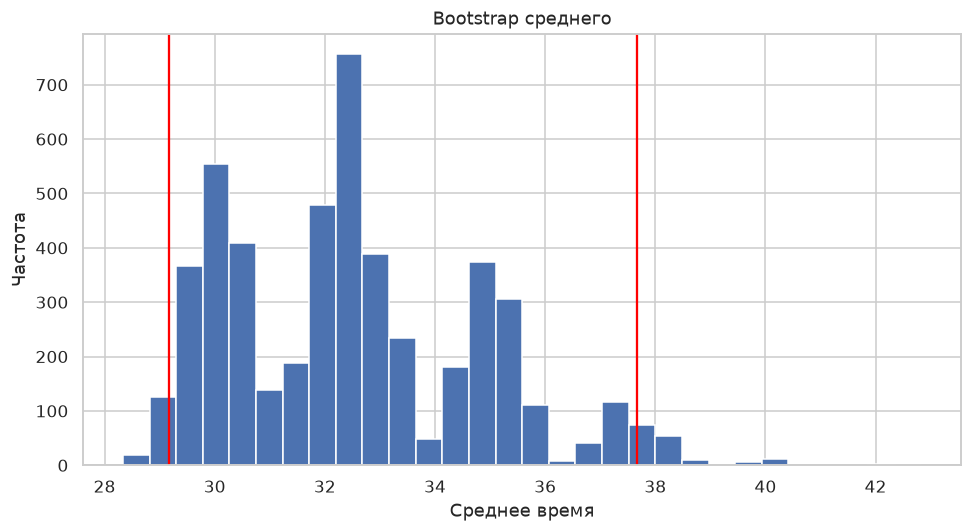

In [10]:
np.random.seed(42)
x = np.array([28, 31, 29, 45, 32, 30])
B = 5000
means = np.empty(B)
for i in range(B):
    means[i] = np.random.choice(x, size=x.size, replace=True).mean()
ci = np.quantile(means, [0.025, 0.975])
print('Среднее:', x.mean(), '; центральный 95% bootstrap ДИ:', ci)
plt.hist(means, bins=30)
plt.axvline(ci[0], color='red')
plt.axvline(ci[1], color='red')
plt.title('Bootstrap среднего')
plt.xlabel('Среднее время')
plt.ylabel('Частота')
show('bootstrap')

Выборка с возвращением имитирует новые выборки из эмпирического распределения. Без возвращения перестановка всех шести элементов не меняла бы среднее. Наблюдение 45 увеличивает правый хвост, особенно при многократном попадании. При n=6 эмпирическое распределение плохо описывает генеральное, поэтому ДИ нестабилен. Корректная частотная интерпретация: при многократном повторении процедуры около 95% построенных таким способом интервалов покрывают фиксированное истинное среднее; конкретному уже вычисленному интервалу вероятность истинности 95% не приписывается.

### 3.2 Гипотезы и ошибки
Обозначим эффект Δ=μB−μA. **H0: Δ≥0**, алгоритм не уменьшает среднее; **H1: Δ<0**. Для расчёта одностороннего критерия используется граничный случай Δ=0.

Ошибка I рода — объявить уменьшение, когда его нет; это ложная тревога, которая может привести к напрасным расходам 5 млн рублей в год. Ошибка II рода — не обнаружить реальное уменьшение; это пропущенный эффект и упущенная выгода.

### 3.3 p-value и решение
p-value — вероятность при H0 и выполненных предпосылках получить статистику не менее экстремальную в направлении альтернативы, чем наблюдаемая. Это не вероятность истинности H0. При p=0,001<0,05 результат статистически значим. Экономия всего трёх секунд при миллионе пользователей может быть статистически обнаружима, но не окупать 5 млн рублей.

Перед внедрением нужны величина эффекта и ДИ, стоимость сэкономленного времени, влияние на конверсию и жалобы, стабильность сегментов и расходы эксплуатации. Рекомендация — не внедрять только на основании p-value: сначала показать практически существенную выгоду и положительную экономику.

### Итоговый вопрос
Если среднее уменьшилось, разброс и p95 выросли, а p90 почти не изменился, уточню:
1. Качество данных: рандомизация, единые периоды, пропуски, сбои измерения, размеры групп, независимость наблюдений.
2. Размер эффекта: абсолютное и относительное изменение среднего с ДИ, заранее выбранная минимально полезная величина.
3. Распределение: гистограммы, сегменты городов и типов заказов, доля нарушений SLA.
4. Выбросы: технические ошибки или реальные задержки; результаты с ними и без них без произвольного удаления.
5. Процентили: ДИ для p90/p95/p99; сколько клиентов стало ждать дольше.
6. Значимость: корректность критерия, множественные проверки, отсутствие подглядывания в A/B-тест.
7. Практический эффект: ценность улучшения для типичного клиента и вред медленному хвосту.
8. Бизнес: чистая выгода после расходов, возвратов и поддержки; допустимость ухудшения SLA.
До ответа на эти вопросы полный запуск не обоснован.

## B Базовый конвейер Pandas

### Формирование и сохранение данных
Создать 15 заказов из условия и сохранить CSV без индекса.

In [11]:
raw_data = {'order_id': list(range(1001, 1016)), 'channel': ['site', 'app', 'app', 'marketplace', 'site', 'app', 'site', 'marketplace', 'app', 'site', 'marketplace', 'app', 'site', 'site', 'marketplace'], 'order_sum': [1200, 2500, 1800, 3200, 900, 1500, 2800, 45000, 2100, 1700, 3600, 1100, 2400, 1900, 3300], 'delivery_time': [25, np.nan, 40, 55, 20, 30, np.nan, 70, 35, 45, 50, 18, 27, np.nan, 60], 'rating': [5, 4, 5, 3, 5, 4, 2, 1, 5, 4, 3, 5, 4, 5, 2]}
df = pd.DataFrame(raw_data)
df.to_csv(DATA / 'online_store_orders.csv', index=False)
display(df)

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5
5,1006,app,1500,30.0,4
6,1007,site,2800,NaN,2
7,1008,marketplace,45000,70.0,1
8,1009,app,2100,35.0,5
9,1010,site,1700,45.0,4


index=False исключает технический индекс строк из CSV. Без него при обратной загрузке появился бы дополнительный столбец Unnamed: 0.

### Загрузка и первичная проверка

In [12]:
store_df = pd.read_csv(DATA / 'online_store_orders.csv')
display(store_df.head())
display(store_df.tail())
print(store_df.shape, store_df.columns.tolist())
store_df.info()
display(store_df.isna().sum())
display(store_df.describe())
assert store_df.shape == (15, 5)

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5


,order_id,channel,order_sum,delivery_time,rating
10,1011,marketplace,3600,50.0,3
11,1012,app,1100,18.0,5
12,1013,site,2400,27.0,4
13,1014,site,1900,NaN,5
14,1015,marketplace,3300,60.0,2


(15, 5) ['order_id', 'channel', 'order_sum', 'delivery_time', 'rating']
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       15 non-null     int64  
 1   channel        15 non-null     str    
 2   order_sum      15 non-null     int64  
 3   delivery_time  12 non-null     float64
 4   rating         15 non-null     int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 732.0 bytes


order_id         0
channel          0
order_sum        0
delivery_time    3
rating           0
dtype: int64

,order_id,order_sum,delivery_time,rating
count,15.000000,15.00000,12.000000,15.000000
mean,1008.000000,5000.00000,39.583333,3.800000
std,4.472136,11096.33144,16.654010,1.320173
min,1001.000000,900.00000,18.000000,1.000000
25%,1004.500000,1600.00000,26.500000,3.000000
50%,1008.000000,2100.00000,37.500000,4.000000
75%,1011.500000,3000.00000,51.250000,5.000000
max,1015.000000,45000.00000,70.000000,5.000000


15 строк, 5 столбцов. Числовые: order_id, order_sum, delivery_time, rating. Три пропуска находятся только в delivery_time; channel — категориальный признак. Максимальная сумма 45000 заметно превосходит остальные заказы.

### Выборка и фильтрация

In [13]:
display(store_df[['order_sum', 'delivery_time']])
display(store_df.iloc[3:8, store_df.columns.get_indexer(['order_sum', 'delivery_time'])])
premium_orders = store_df[(store_df.order_sum > 2000) & (store_df.rating == 5)]
display(premium_orders)

,order_sum,delivery_time
0,1200,25.0
1,2500,NaN
2,1800,40.0
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0
8,2100,35.0
9,1700,45.0


,order_sum,delivery_time
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0


,order_id,channel,order_sum,delivery_time,rating
8,1009,app,2100,35.0,5


iloc[3:8] включает индексы от 3 до 7. Оператор & объединяет булевы Series поэлементно; and требует единственное логическое значение и для Series неоднозначен. Под фильтр попадает заказ 1009.

### Статистики и группировка

In [14]:
mean_delivery = store_df.delivery_time.mean()
median_delivery = store_df.delivery_time.median()
print('Доставка среднее/медиана:', mean_delivery, median_delivery)
display(store_df.rating.value_counts())
store_df['is_high_value'] = store_df.order_sum > 3000
display(store_df[['order_id', 'order_sum', 'is_high_value']])
channel_stats = store_df.groupby('channel').order_sum.mean().sort_values(ascending=False)
display(channel_stats)
print('Высокая стоимость:', store_df.is_high_value.sum())
print('Средняя сумма с выбросом/без:', store_df.order_sum.mean(), store_df.loc[store_df.order_sum < 45000, 'order_sum'].mean())

Доставка среднее/медиана: 39.583333333333336 37.5


rating
5    6
4    4
3    2
2    2
1    1
Name: count, dtype: int64

,order_id,order_sum,is_high_value
0,1001,1200,False
1,1002,2500,False
2,1003,1800,False
3,1004,3200,True
4,1005,900,False
5,1006,1500,False
6,1007,2800,False
7,1008,45000,True
8,1009,2100,False
9,1010,1700,False


channel
marketplace    13775.000000
site            1816.666667
app             1800.000000
Name: order_sum, dtype: float64

Высокая стоимость: 4
Средняя сумма с выбросом/без: 5000.0 2142.8571428571427


В наборе 15 заказов и 3 пропуска времени доставки; среднее время 39.58 мин, медиана 37.50 мин (пропуски исключены). Средняя сумма по каналам: marketplace: 13775.00 руб.; site: 1816.67 руб.; app: 1800.00 руб. Четыре заказа дороже 3000 руб. Заказ на 45000 руб. сильно повышает среднее marketplace; это не доказывает преимущество типичного заказа этого канала. Чаще всего встречается оценка 5. Среднее чувствительнее медианы к экстремальным значениям.

### Дополнительное задание Гистограмма

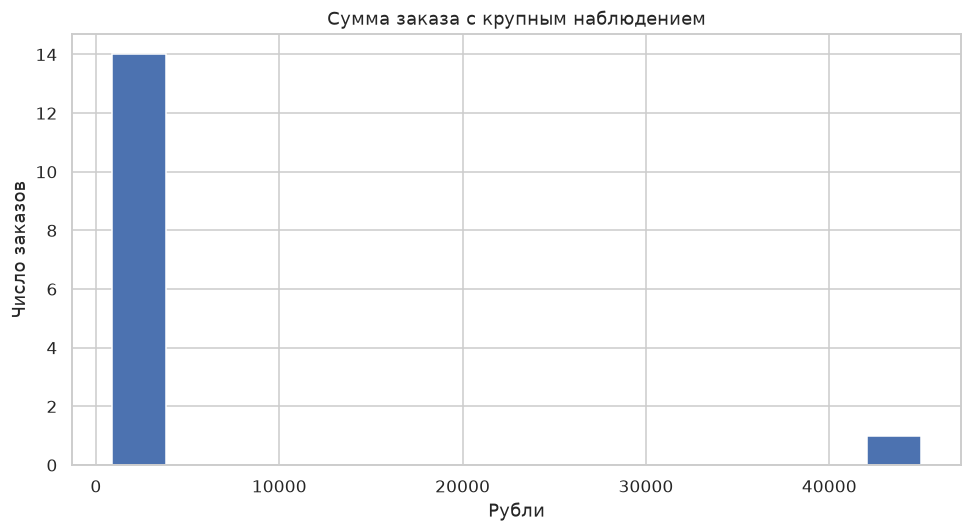

In [15]:
store_df.order_sum.plot.hist(bins=15)
plt.title('Сумма заказа с крупным наблюдением')
plt.xlabel('Рубли')
plt.ylabel('Число заказов')
show('order_sum')

Заказ 45000 растягивает ось и сжимает основную массу распределения. Для дополнительной детализации полезны логарифмическая ось или отдельный график основной группы, но исходное наблюдение нельзя удалять без проверки.

## C Анализ интернет-магазина

### 0 Генерация 3000 заказов
Учебная симуляция, а не реальные продажи. cost — полная себестоимость заказа, чтобы profit=revenue−cost имел согласованные единицы.

In [16]:
np.random.seed(2024)
n = 3000
cities = ['Москва', 'Санкт-Петербург', 'Казань', 'Екатеринбург', 'Челябинск']
categories = ['Электроника', 'Одежда', 'Дом', 'Красота', 'Спорт']
cat = np.random.choice(categories, n)
price = np.round(np.random.lognormal(7.5, 0.9, n), 2)
quantity = np.random.randint(1, 7, n)
df = pd.DataFrame({'order_id': np.arange(1, n + 1), 'order_date': pd.Timestamp('2023-01-01') + pd.to_timedelta(np.random.randint(0, 731, n), unit='D'), 'customer_id': np.random.randint(1, 1201, n), 'city': np.random.choice(cities, n), 'age': np.random.randint(16, 76, n).astype(float), 'is_vip': np.random.choice([True, False], n, p=[0.2, 0.8]), 'product_name': np.char.add(cat.astype(str), np.random.choice([' A', ' B', ' C', ' D'], n)), 'category': cat, 'quantity': quantity, 'price': price, 'discount': np.random.choice([0, 0.05, 0.1, 0.2, 0.25, 0.3], n), 'cost': np.round(price * quantity * np.random.uniform(0.55, 0.95, n), 2), 'status': np.random.choice(['Доставлен', 'Отменён', 'Возврат'], n, p=[0.8, 0.12, 0.08]), 'payment': np.random.choice(['Карта', 'Онлайн', 'Наличные'], n)})
df.loc[np.random.choice(n, 30, replace=False), 'age'] = np.nan
df.to_csv(DATA / 'orders_raw.csv', index=False)
display(df.head())
display(df.tail())
print('Размер:', df.shape)
df.info()
display(df.describe())
display(df.isna().sum())
print('Уникальных клиентов/товаров:', df.customer_id.nunique(), df.product_name.nunique())
for c in ['city', 'category', 'payment']:
    print(c, df[c].unique())
assert df.age.isna().sum() == 30 and len(df) == 3000

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.00,4680.44,Доставлен,Наличные
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн
2,3,2023-06-14,368,Санкт-Петербург,23.0,False,Электроника D,Электроника,2,2542.11,0.05,3193.55,Доставлен,Карта
3,4,2024-03-29,853,Санкт-Петербург,70.0,False,Электроника D,Электроника,1,5095.71,0.00,3220.85,Доставлен,Онлайн
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.10,3374.72,Доставлен,Карта


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
2995,2996,2024-04-28,147,Челябинск,73.0,True,Одежда D,Одежда,4,597.16,0.00,1811.15,Доставлен,Карта
2996,2997,2024-10-30,909,Санкт-Петербург,65.0,True,Дом D,Дом,1,2817.52,0.25,2087.28,Доставлен,Карта
2997,2998,2024-09-04,1195,Екатеринбург,61.0,False,Красота A,Красота,4,2148.17,0.05,6160.00,Доставлен,Наличные
2998,2999,2023-02-12,412,Казань,62.0,False,Красота A,Красота,5,641.10,0.05,2739.98,Доставлен,Карта
2999,3000,2024-01-22,854,Санкт-Петербург,43.0,False,Электроника D,Электроника,1,933.93,0.10,824.15,Доставлен,Онлайн


Размер: (3000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      3000 non-null   int64         
 1   order_date    3000 non-null   datetime64[us]
 2   customer_id   3000 non-null   int64         
 3   city          3000 non-null   str           
 4   age           2970 non-null   float64       
 5   is_vip        3000 non-null   bool          
 6   product_name  3000 non-null   str           
 7   category      3000 non-null   str           
 8   quantity      3000 non-null   int64         
 9   price         3000 non-null   float64       
 10  discount      3000 non-null   float64       
 11  cost          3000 non-null   float64       
 12  status        3000 non-null   str           
 13  payment       3000 non-null   str           
dtypes: bool(1), datetime64[us](1), float64(4), int64(3), str(5)
memory usage: 307.7 

,order_id,order_date,customer_id,age,quantity,price,discount,cost
count,3000.000000,3000,3000.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,2023-12-31 12:19:40.800000,609.078000,45.770370,3.470000,2671.327930,0.145683,7001.466780
min,1.000000,2023-01-01 00:00:00,2.000000,16.000000,1.000000,68.270000,0.000000,61.420000
25%,750.750000,2023-06-27 00:00:00,306.000000,31.000000,2.000000,972.660000,0.050000,1888.845000
50%,1500.500000,2024-01-03 00:00:00,614.000000,46.000000,3.000000,1806.155000,0.100000,4018.710000
75%,2250.250000,2024-07-03 06:00:00,909.250000,61.000000,5.000000,3379.365000,0.250000,8476.825000
max,3000.000000,2024-12-31 00:00:00,1200.000000,75.000000,6.000000,31062.680000,0.300000,114035.930000
std,866.169729,NaN,350.055062,17.480658,1.702175,2773.592434,0.108241,8904.165125


order_id         0
order_date       0
customer_id      0
city             0
age             30
is_vip           0
product_name     0
category         0
quantity         0
price            0
discount         0
cost             0
status           0
payment          0
dtype: int64

Уникальных клиентов/товаров: 1099 20
city <StringArray>
['Казань', 'Москва', 'Санкт-Петербург', 'Екатеринбург', 'Челябинск']
Length: 5, dtype: str
category <StringArray>
['Электроника', 'Дом', 'Красота', 'Спорт', 'Одежда']
Length: 5, dtype: str
payment <StringArray>
['Наличные', 'Онлайн', 'Карта']
Length: 3, dtype: str


### 2 Подготовка

In [17]:
df['order_date'] = pd.to_datetime(df.order_date)
df['year'] = df.order_date.dt.year
df['month'] = df.order_date.dt.month
df['revenue'] = df.price * df.quantity * (1 - df.discount)
df['profit'] = df.revenue - df.cost
df['is_real_sale'] = df.status.eq('Доставлен')
median_age = df.age.median()
df['age'] = df.age.fillna(median_age)
df['age_group'] = pd.cut(df.age, bins=[0, 18, 30, 45, 60, 100], labels=['до 18', '18–30', '31–45', '46–60', '60+'])
display(df.age_group.value_counts(sort=False))
print('Пропусков после:', df.age.isna().sum(), 'Медиана:', median_age)
print('Убыточных заказов:', (df.profit < 0).sum())
display(df.head())
df.to_csv(DATA / 'orders_prepared.csv', index=False)

age_group
до 18    146
18–30    596
31–45    727
46–60    770
60+      761
Name: count, dtype: int64

Пропусков после: 0 Медиана: 46.0
Убыточных заказов: 774


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.00,4680.44,Доставлен,Наличные,2024,7,6080.130,1399.690,True,60+
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн,2023,4,3310.342,335.852,True,60+
2,3,2023-06-14,368,Санкт-Петербург,23.0,False,Электроника D,Электроника,2,2542.11,0.05,3193.55,Доставлен,Карта,2023,6,4830.009,1636.459,True,18–30
3,4,2024-03-29,853,Санкт-Петербург,70.0,False,Электроника D,Электроника,1,5095.71,0.00,3220.85,Доставлен,Онлайн,2024,3,5095.710,1874.860,True,60+
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.10,3374.72,Доставлен,Карта,2024,3,3961.116,586.396,True,60+


Прибыль может быть отрицательна, если скидка уменьшила выручку ниже полной себестоимости. Для фактической выручки далее используются только доставленные заказы; отменённые и возвращённые не считаются реализованными продажами. Группы возраста воспроизводят границы из условия: интервал с подписью «до 18» включает 18, следующий — (18,30]. Возраст задан на уровне заказа; при реальной работе его следовало бы согласовать по клиенту.

### 3 Все фильтры и экстремальные значения

In [18]:
filters = {'quantity>3': df.quantity > 3, 'Москва': df.city.eq('Москва'), 'VIP': df.is_vip, 'price>5000': df.price > 5000, 'discount>20%': df.discount > 0.2, 'Москва и revenue>5000': df.city.eq('Москва') & (df.revenue > 5000), 'VIP Электроника': df.is_vip & df.category.eq('Электроника'), 'Доставлен Онлайн': df.is_real_sale & df.payment.eq('Онлайн'), '2024': df.year.eq(2024), 'Январь 2024': df.year.eq(2024) & df.month.eq(1)}
for name, mask in filters.items():
    print(name, '—', mask.sum())
    display(df.loc[mask].head())
display(df.status.value_counts())
for col, kind in [('revenue', 'max'), ('discount', 'max'), ('profit', 'max'), ('age', 'min'), ('age', 'max')]:
    idx = getattr(df[col], 'idx' + kind)()
    print(col, kind)
    display(df.loc[[idx]])

quantity>3 — 1459


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.1,3374.72,Доставлен,Карта,2024,3,3961.116,586.396,True,60+
6,7,2024-05-09,408,Казань,61.0,False,Одежда A,Одежда,6,5451.35,0.1,20521.13,Доставлен,Карта,2024,5,29437.290,8916.160,True,60+
11,12,2023-11-11,393,Казань,46.0,False,Дом B,Дом,6,874.16,0.1,4633.98,Возврат,Карта,2023,11,4720.464,86.484,False,46–60
12,13,2023-09-03,1138,Санкт-Петербург,36.0,False,Электроника B,Электроника,5,4583.62,0.1,20905.60,Доставлен,Наличные,2023,9,20626.290,-279.310,True,31–45
13,14,2023-11-23,1020,Челябинск,70.0,False,Спорт B,Спорт,6,2792.74,0.3,9418.40,Доставлен,Карта,2023,11,11729.508,2311.108,True,60+


Москва — 588


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.3,2974.49,Доставлен,Онлайн,2023,4,3310.342,335.852,True,60+
17,18,2023-06-09,1134,Москва,71.0,False,Спорт D,Спорт,6,6770.05,0.3,26483.65,Отменён,Карта,2023,6,28434.210,1950.560,False,60+
24,25,2023-01-08,416,Москва,29.0,False,Одежда D,Одежда,2,3986.97,0.2,6834.51,Отменён,Наличные,2023,1,6379.152,-455.358,False,18–30
31,32,2023-06-14,988,Москва,66.0,False,Дом B,Дом,1,4411.83,0.1,2732.87,Доставлен,Онлайн,2023,6,3970.647,1237.777,True,60+
32,33,2024-11-10,741,Москва,58.0,False,Одежда B,Одежда,5,4079.18,0.2,12736.23,Отменён,Карта,2024,11,16316.720,3580.490,False,46–60


VIP — 593


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн,2023,4,3310.3420,335.8520,True,60+
7,8,2024-07-19,593,Екатеринбург,28.0,True,Одежда B,Одежда,2,1165.48,0.00,1823.29,Доставлен,Карта,2024,7,2330.9600,507.6700,True,18–30
8,9,2024-07-21,745,Челябинск,33.0,True,Спорт B,Спорт,1,1030.02,0.20,973.58,Доставлен,Онлайн,2024,7,824.0160,-149.5640,True,31–45
23,24,2024-08-01,464,Челябинск,61.0,True,Дом A,Дом,3,3361.85,0.05,7708.61,Доставлен,Онлайн,2024,8,9581.2725,1872.6625,True,60+
26,27,2023-11-25,243,Челябинск,27.0,True,Красота A,Красота,2,844.76,0.20,1101.41,Доставлен,Наличные,2023,11,1351.6160,250.2060,True,18–30


... (21 outputs left out)

age min


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
86,87,2024-05-01,489,Екатеринбург,16.0,False,Спорт C,Спорт,4,271.79,0.1,683.52,Отменён,Онлайн,2024,5,978.444,294.924,False,до 18


age max


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.0,4680.44,Доставлен,Наличные,2024,7,6080.13,1399.69,True,60+


### 4 Группировки
Сначала показатели всех заказов по условию, затем отдельно показатели фактических продаж.

In [19]:
display(df.groupby('category').revenue.sum())
display(df.groupby('category').revenue.mean())
display(df.groupby('category').size())
display(df.groupby('category').discount.mean())
display(df.groupby(['category', 'city']).revenue.sum())
display(df.loc[df.is_vip].groupby('city').revenue.mean())
display(df.groupby(['city', 'payment']).size().unstack(fill_value=0))
summary = df.groupby('category').agg(orders=('order_id', 'count'), revenue=('revenue', 'sum'), avg_revenue=('revenue', 'mean'), avg_discount=('discount', 'mean'), profit=('profit', 'sum'))
display(summary)
real = df.loc[df.is_real_sale].copy()
actual = real.groupby('category').revenue.sum().sort_values(ascending=False)
display(actual)

category
Дом            4.360537e+06
Красота        5.057605e+06
Одежда         5.134924e+06
Спорт          4.850438e+06
Электроника    4.589345e+06
Name: revenue, dtype: float64

category
Дом            7340.972021
Красота        8237.141140
Одежда         8630.125034
Спорт          7925.552916
Электроника    7845.033604
Name: revenue, dtype: float64

category
Дом            594
Красота        614
Одежда         595
Спорт          612
Электроника    585
dtype: int64

category
Дом            0.146465
Красота        0.140472
Одежда         0.146050
Спорт          0.149673
Электроника    0.145812
Name: discount, dtype: float64

category     city           
Дом          Екатеринбург       6.899633e+05
             Казань             9.762524e+05
             Москва             8.306662e+05
             Санкт-Петербург    6.689433e+05
             Челябинск          1.194712e+06
Красота      Екатеринбург       9.904482e+05
             Казань             1.099871e+06
             Москва             9.414682e+05
             Санкт-Петербург    1.184909e+06
             Челябинск          8.409085e+05
Одежда       Екатеринбург       9.154884e+05
             Казань             9.620211e+05
             Москва             1.128438e+06
             Санкт-Петербург    1.105011e+06
             Челябинск          1.023965e+06
Спорт        Екатеринбург       8.956106e+05
             Казань             1.086239e+06
             Москва             9.497528e+05
             Санкт-Петербург    1.016369e+06
             Челябинск          9.024676e+05
Электроника  Екатеринбург       1.059577e+06
             Казань       

city
Екатеринбург       7681.281953
Казань             8670.668967
Москва             6720.377958
Санкт-Петербург    8087.029725
Челябинск          7481.589423
Name: revenue, dtype: float64

payment,Карта,Наличные,Онлайн
city,,,
Екатеринбург,193,203,193
Казань,220,182,218
Москва,187,198,203
Санкт-Петербург,207,194,189
Челябинск,220,198,195


,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,594,4.360537e+06,7340.972021,0.146465,624632.2305
Красота,614,5.057605e+06,8237.141140,0.140472,613631.0700
Одежда,595,5.134924e+06,8630.125034,0.146050,594708.6150
Спорт,612,4.850438e+06,7925.552916,0.149673,611549.2345
Электроника,585,4.589345e+06,7845.033604,0.145812,543927.9885


category
Одежда         4441386.472
Спорт          3832243.696
Красота        3831999.559
Электроника    3574414.163
Дом            3490502.049
Name: revenue, dtype: float64

### 5 Девять визуализаций

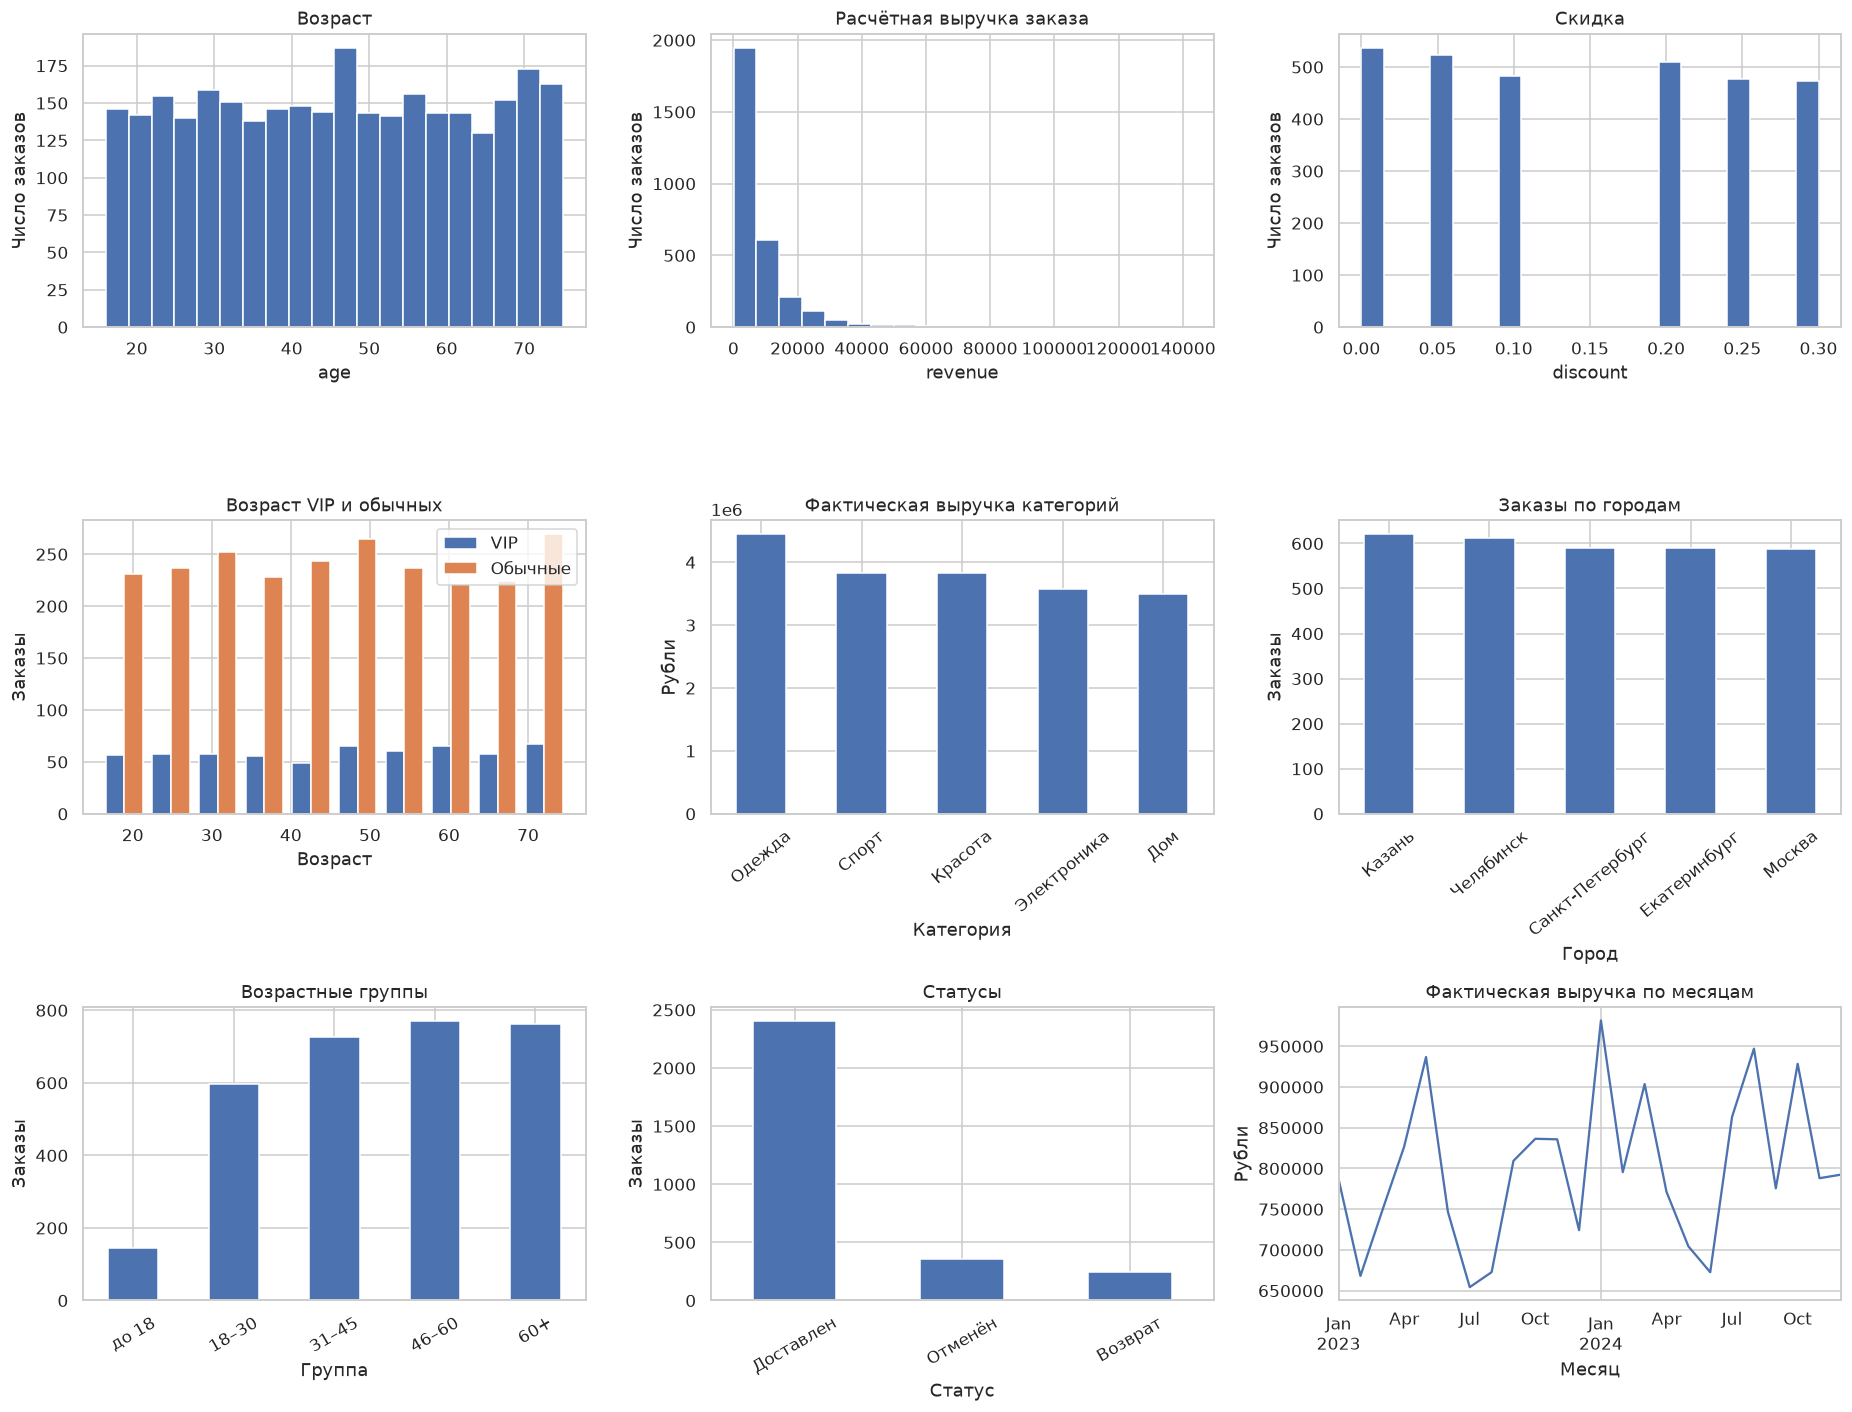

In [20]:
fig, ax = plt.subplots(3, 3, figsize=(17, 13))
for a, col, title in zip(ax.flat[:3], ['age', 'revenue', 'discount'], ['Возраст', 'Расчётная выручка заказа', 'Скидка']):
    a.hist(df[col], bins=20)
    a.set(title=title, xlabel=col, ylabel='Число заказов')
ax[1, 0].hist([df.loc[df.is_vip, 'age'], df.loc[~df.is_vip, 'age']], label=['VIP', 'Обычные'], bins=10)
ax[1, 0].legend()
ax[1, 0].set(title='Возраст VIP и обычных', xlabel='Возраст', ylabel='Заказы')
actual.plot.bar(ax=ax[1, 1], rot=40)
ax[1, 1].set(title='Фактическая выручка категорий', xlabel='Категория', ylabel='Рубли')
df.city.value_counts().plot.bar(ax=ax[1, 2], rot=40)
ax[1, 2].set(title='Заказы по городам', xlabel='Город', ylabel='Заказы')
df.age_group.value_counts(sort=False).plot.bar(ax=ax[2, 0], rot=30)
ax[2, 0].set(title='Возрастные группы', xlabel='Группа', ylabel='Заказы')
df.status.value_counts().plot.bar(ax=ax[2, 1], rot=30)
ax[2, 1].set(title='Статусы', xlabel='Статус', ylabel='Заказы')
monthly = real.groupby(real.order_date.dt.to_period('M')).revenue.sum()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=ax[2, 2])
ax[2, 2].set(title='Фактическая выручка по месяцам', xlabel='Месяц', ylabel='Рубли')
show('store_dashboard')

### 6 Мини анализ

In [21]:
vip_share = real.loc[real.is_vip, 'revenue'].sum() / real.revenue.sum()
print('Всего заказов:', len(df), 'Доставлено:', len(real), 'Расчётная сумма всех:', df.revenue.sum(), 'Фактическая:', real.revenue.sum(), 'Средняя доставленного:', real.revenue.mean())
print('Максимум/минимум категорий:', actual.idxmax(), actual.idxmin(), 'Доля VIP:', vip_share)
df['discount_group'] = pd.cut(df.discount, [-0.001, 0.1, 0.2, 0.31], labels=['0–10%', '>10–20%', '>20–30%'])
discount_stats = df.groupby('discount_group', observed=True).revenue.agg(['count', 'mean'])
display(discount_stats)
losses = pd.crosstab(df.category, df.status).reindex(columns=['Отменён', 'Возврат'], fill_value=0)
losses['Всего'] = losses.sum(axis=1)
display(losses)

Всего заказов: 3000 Доставлено: 2403 Расчётная сумма всех: 23992849.4785 Фактическая: 19170545.939 Средняя доставленного: 7977.75528048273
Максимум/минимум категорий: Одежда Дом Доля VIP: 0.19007671247833416


,count,mean
discount_group,,
0–10%,1542,9041.186217
>10–20%,509,7427.773202
>20–30%,949,6607.590908


status,Отменён,Возврат,Всего
category,,,
Дом,68,52,120
Красота,85,53,138
Одежда,62,47,109
Спорт,68,41,109
Электроника,73,48,121


Всего 3000 заказов, из них 2403 доставлены; отмены и возвраты исключены из фактической выручки 19,170,545.94 руб. Средняя выручка доставленного заказа 7977.76 руб. Наибольшая фактическая выручка у категории «Одежда», наименьшая — «Дом». Самое большое число заказов у города «Казань». VIP дают 19.0% фактической выручки. Сравнение скидочных групп наблюдательное: различия среднего чека зависят также от цены и количества, причинный эффект скидки не установлен. Больше всего отмен и возвратов в абсолютных числах у «Красота»; дополнительно нужны доли от заказов категории, анализ маржи и проверка результатов на реальных данных.

### Контрольные вопросы
1. DataFrame — двумерная таблица с именованными столбцами и индексом.
2. loc выбирает по меткам (правая метка среза включается), iloc — по позициям (правая граница исключается).
3. groupby разделяет наблюдения на группы; agg задаёт одно или несколько агрегирований.
4. mean чувствителен к экстремумам, median — центральная порядковая величина.
5. Пропуски находятся isna; методы: удаление, константа, среднее/медиана/мода, прогнозное заполнение.
6. pd.cut разбивает числовой признак на интервалы; value_counts считает частоты; idxmax возвращает индекс первого максимума.
7. Несколько фильтров объединяются &, | и скобками; качество данных проверяется до анализа, чтобы избежать искажённых выводов.
8. revenue — выручка, profit — выручка минус затраты. Отмены и возвраты не являются реализованной выручкой в этой модели.
9. Визуализация обнаруживает распределения и зависимости; Git хранит версии, позволяет видеть изменения и воспроизводить этапы работы.